# GenVerOpt reproduction — Stage 4: pairwise verifier baseline on the MM-IQ usable subset
Stage 3e results: **1,413 usable items** (1,261 skipped for non-"question mark" prompts, 34 not parsed, 2 empty question). Answers are balanced (A 339, B 368, C 353, D 353). Cleaning applied to 3,924 of 5,652 crops (mean 24% of ink removed). 5 groups of items share exactly identical option sets, so this notebook rebuilds the split with those groups kept together.

**What this is.** An *adapted* verifier: a CNN scores each (question image, option crop) pair; the highest-scoring option is the prediction. The paper instead inserts the option into the missing square of the grid, and trains with Reptile across puzzle categories (impossible here: no category labels). Loss is per-candidate binary cross-entropy in its standard form (the paper's Eq. 2 as printed is malformed).

**Controls included**
- *option-only* model: if it beats chance, options carry shortcut cues unrelated to the question.
- *shuffled-question* test: a model that uses the question should drop toward chance when the question comes from a different puzzle.

**Reading the numbers.** Chance is 25%. With ~210 test items the 95% interval on a single accuracy is about ±6 points, so anything under roughly 31% is indistinguishable from chance. Not comparable with the paper's 68%.

**Status:** generated; the split logic was tested on random data here, but the PyTorch code could not be run in my sandbox (no torch available), so cells 3–5 are untested. Expect possible bugs and send me any traceback.

In [2]:
# From genveropt_stage3e.ipynb
!pip -q install datasets pillow matplotlib scipy
import random, re, numpy as np
from collections import Counter
from PIL import Image
from scipy import ndimage as ndi
from datasets import load_dataset
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)
ds = load_dataset("afdsafas/MMIQ")["train"]

data/train_1.parquet: reconstructing file:   0%|          |  0.00B /  116MB            

data/train_1.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2710 [00:00<?, ? examples/s]

In [3]:
# From genveropt_stage3e.ipynb
MAX_SIDE = 1600

def to_rgb_white(im):
    """Composite transparency on white (naive convert() turns transparent pixels black), then cap size."""
    if im.mode in ("RGBA", "LA") or (im.mode == "P" and "transparency" in im.info):
        im = im.convert("RGBA")
        bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
        bg.alpha_composite(im)
        im = bg.convert("RGB")
    else:
        im = im.convert("RGB")
    s = max(im.size)
    if s > MAX_SIDE:
        f = MAX_SIDE / s
        im = im.resize((max(1, round(im.width * f)), max(1, round(im.height * f))), Image.LANCZOS)
    return im

def runs(mask, min_gap):
    idx = np.flatnonzero(mask)
    if idx.size == 0: return []
    out, s, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - prev > min_gap:
            out.append((int(s), int(prev) + 1)); s = i
        prev = i
    out.append((int(s), int(prev) + 1))
    return out

def thin_rules(ink):
    """Boolean per row: True for thin, nearly full-width horizontal lines (frame borders)."""
    h, w = ink.shape
    dense = ink.mean(1) > 0.6
    rule = np.zeros(h, bool)
    for a, b in runs(dense, 0):
        if b - a <= max(3, int(0.012 * h)): rule[a:b] = True
    return rule

def extract(im):
    """Return dict(ok, reason, crops(4), question(masked), info). Option positions come from the A-D label glyphs."""
    im = to_rgb_white(im)
    g = np.asarray(im.convert("L")); ink = g < 200
    h, w = ink.shape
    rule = thin_rules(ink)
    bands = runs(ink.any(1) & ~rule, 1)
    if len(bands) < 2: return dict(ok=False, reason="few_bands", img=im)
    l0, l1 = bands[-1]
    cols = runs(ink[l0:l1].any(0), max(3, int(0.01 * w)))
    if len(cols) != 4: return dict(ok=False, reason=f"clusters={len(cols)}", img=im)
    if (l1 - l0) > 0.25 * h: return dict(ok=False, reason="label_band_too_tall", img=im)
    cx = np.array([(a + b) / 2 for a, b in cols])
    cw = np.mean([b - a for a, b in cols])
    if cw > 0.2 * w: return dict(ok=False, reason="clusters_too_wide", img=im)
    d = np.diff(cx)
    if d.std() / d.mean() > 0.35: return dict(ok=False, reason="uneven_spacing", img=im)
    xe = np.concatenate([[max(0, cx[0] - d[0] / 2)], (cx[:-1] + cx[1:]) / 2, [min(w, cx[-1] + d[-1] / 2)]]).astype(int)
    o0, o1 = bands[-2]
    # extend vertically to include any rule rows touching the option band, then crop
    crops = [im.crop((int(xe[i]), o0, int(xe[i + 1]), o1)) for i in range(4)]
    q = np.asarray(im).copy()
    q[o0:h, xe[0]:xe[-1]] = 255
    return dict(ok=True, reason="ok", img=im, crops=crops, question=Image.fromarray(q),
                info=dict(label_band=(l0, l1), option_band=(o0, o1), xe=xe.tolist()))

In [4]:
# From genveropt_stage3e.ipynb
def make_question(r):
    """Blank the option region including the option frame, using ink runs that overlap the option columns."""
    im = r["img"]; arr = np.asarray(im).copy()
    ink = np.asarray(im.convert("L")) < 200
    h, w = ink.shape
    o0, o1 = r["info"]["option_band"]; xe = r["info"]["xe"]
    xl, xr = xe[0], xe[-1]
    cr = runs(ink[o0:o1].any(0), max(2, int(0.008 * w)))
    tol = 0.35 * float(np.mean(np.diff(xe)))
    l, rr, changed = xl, xr, True
    while changed:                                       # grow outward over ink runs within tol of the current extent (frame sides)
        changed = False
        for p, q in cr:
            if q > l - tol and p < rr + tol and (p < l or q > rr):
                l, rr, changed = min(l, p), max(rr, q), True
    if (rr - l) <= 1.35 * (xe[-1] - xe[0]):             # guard: do not swallow question cells that touch the options
        xl, xr = l, rr
    rule = thin_rules(ink)
    y0 = o0
    while y0 > 0 and rule[max(0, y0 - 4):y0].any():
        y0 = max(0, y0 - 4) + int(np.flatnonzero(rule[max(0, y0 - 4):y0])[0])
    arr[y0:h, xl:xr] = 255
    return Image.fromarray(arr)

def clean_crop2(c, max_removed=0.6):
    """Remove only components that touch the crop edge AND are line-like (thin) or small slivers.
    Returns (grayscale PIL image, removed_ink_fraction, applied). Falls back to the raw crop if too much would be removed."""
    g = np.asarray(c.convert("L"))
    ink = g < 200
    h, w = ink.shape
    total = int(ink.sum())
    if total == 0: return Image.fromarray(g), 0.0, False
    lab, _ = ndi.label(ink, structure=np.ones((3, 3)))
    remove = np.zeros_like(ink)
    for k, sl in enumerate(ndi.find_objects(lab), start=1):
        ys, xs = sl
        bh, bw = ys.stop - ys.start, xs.stop - xs.start
        if not (ys.start == 0 or xs.start == 0 or ys.stop == h or xs.stop == w): continue
        thin = min(bh, bw) <= 0.08 * max(h, w) and max(bh, bw) >= 5 * min(bh, bw) and max(bh, bw) >= 0.5 * min(h, w)
        sliver = bw < 0.08 * w and bh < 0.4 * h
        if thin or sliver: remove |= (lab == k)
    frac = float((remove & ink).sum()) / total
    if frac > max_removed: return Image.fromarray(g), frac, False
    out = g.copy(); out[ndi.binary_dilation(remove, iterations=1)] = 255
    return Image.fromarray(out), frac, bool(remove.any())

def letterbox(img, H, W, pad_val=255):
    g = img.convert("L"); s = min(H / g.height, W / g.width)
    g = g.resize((max(1, round(g.width * s)), max(1, round(g.height * s))), Image.LANCZOS)
    canvas = Image.new("L", (W, H), pad_val); canvas.paste(g, ((W - g.width) // 2, (H - g.height) // 2))
    return canvas

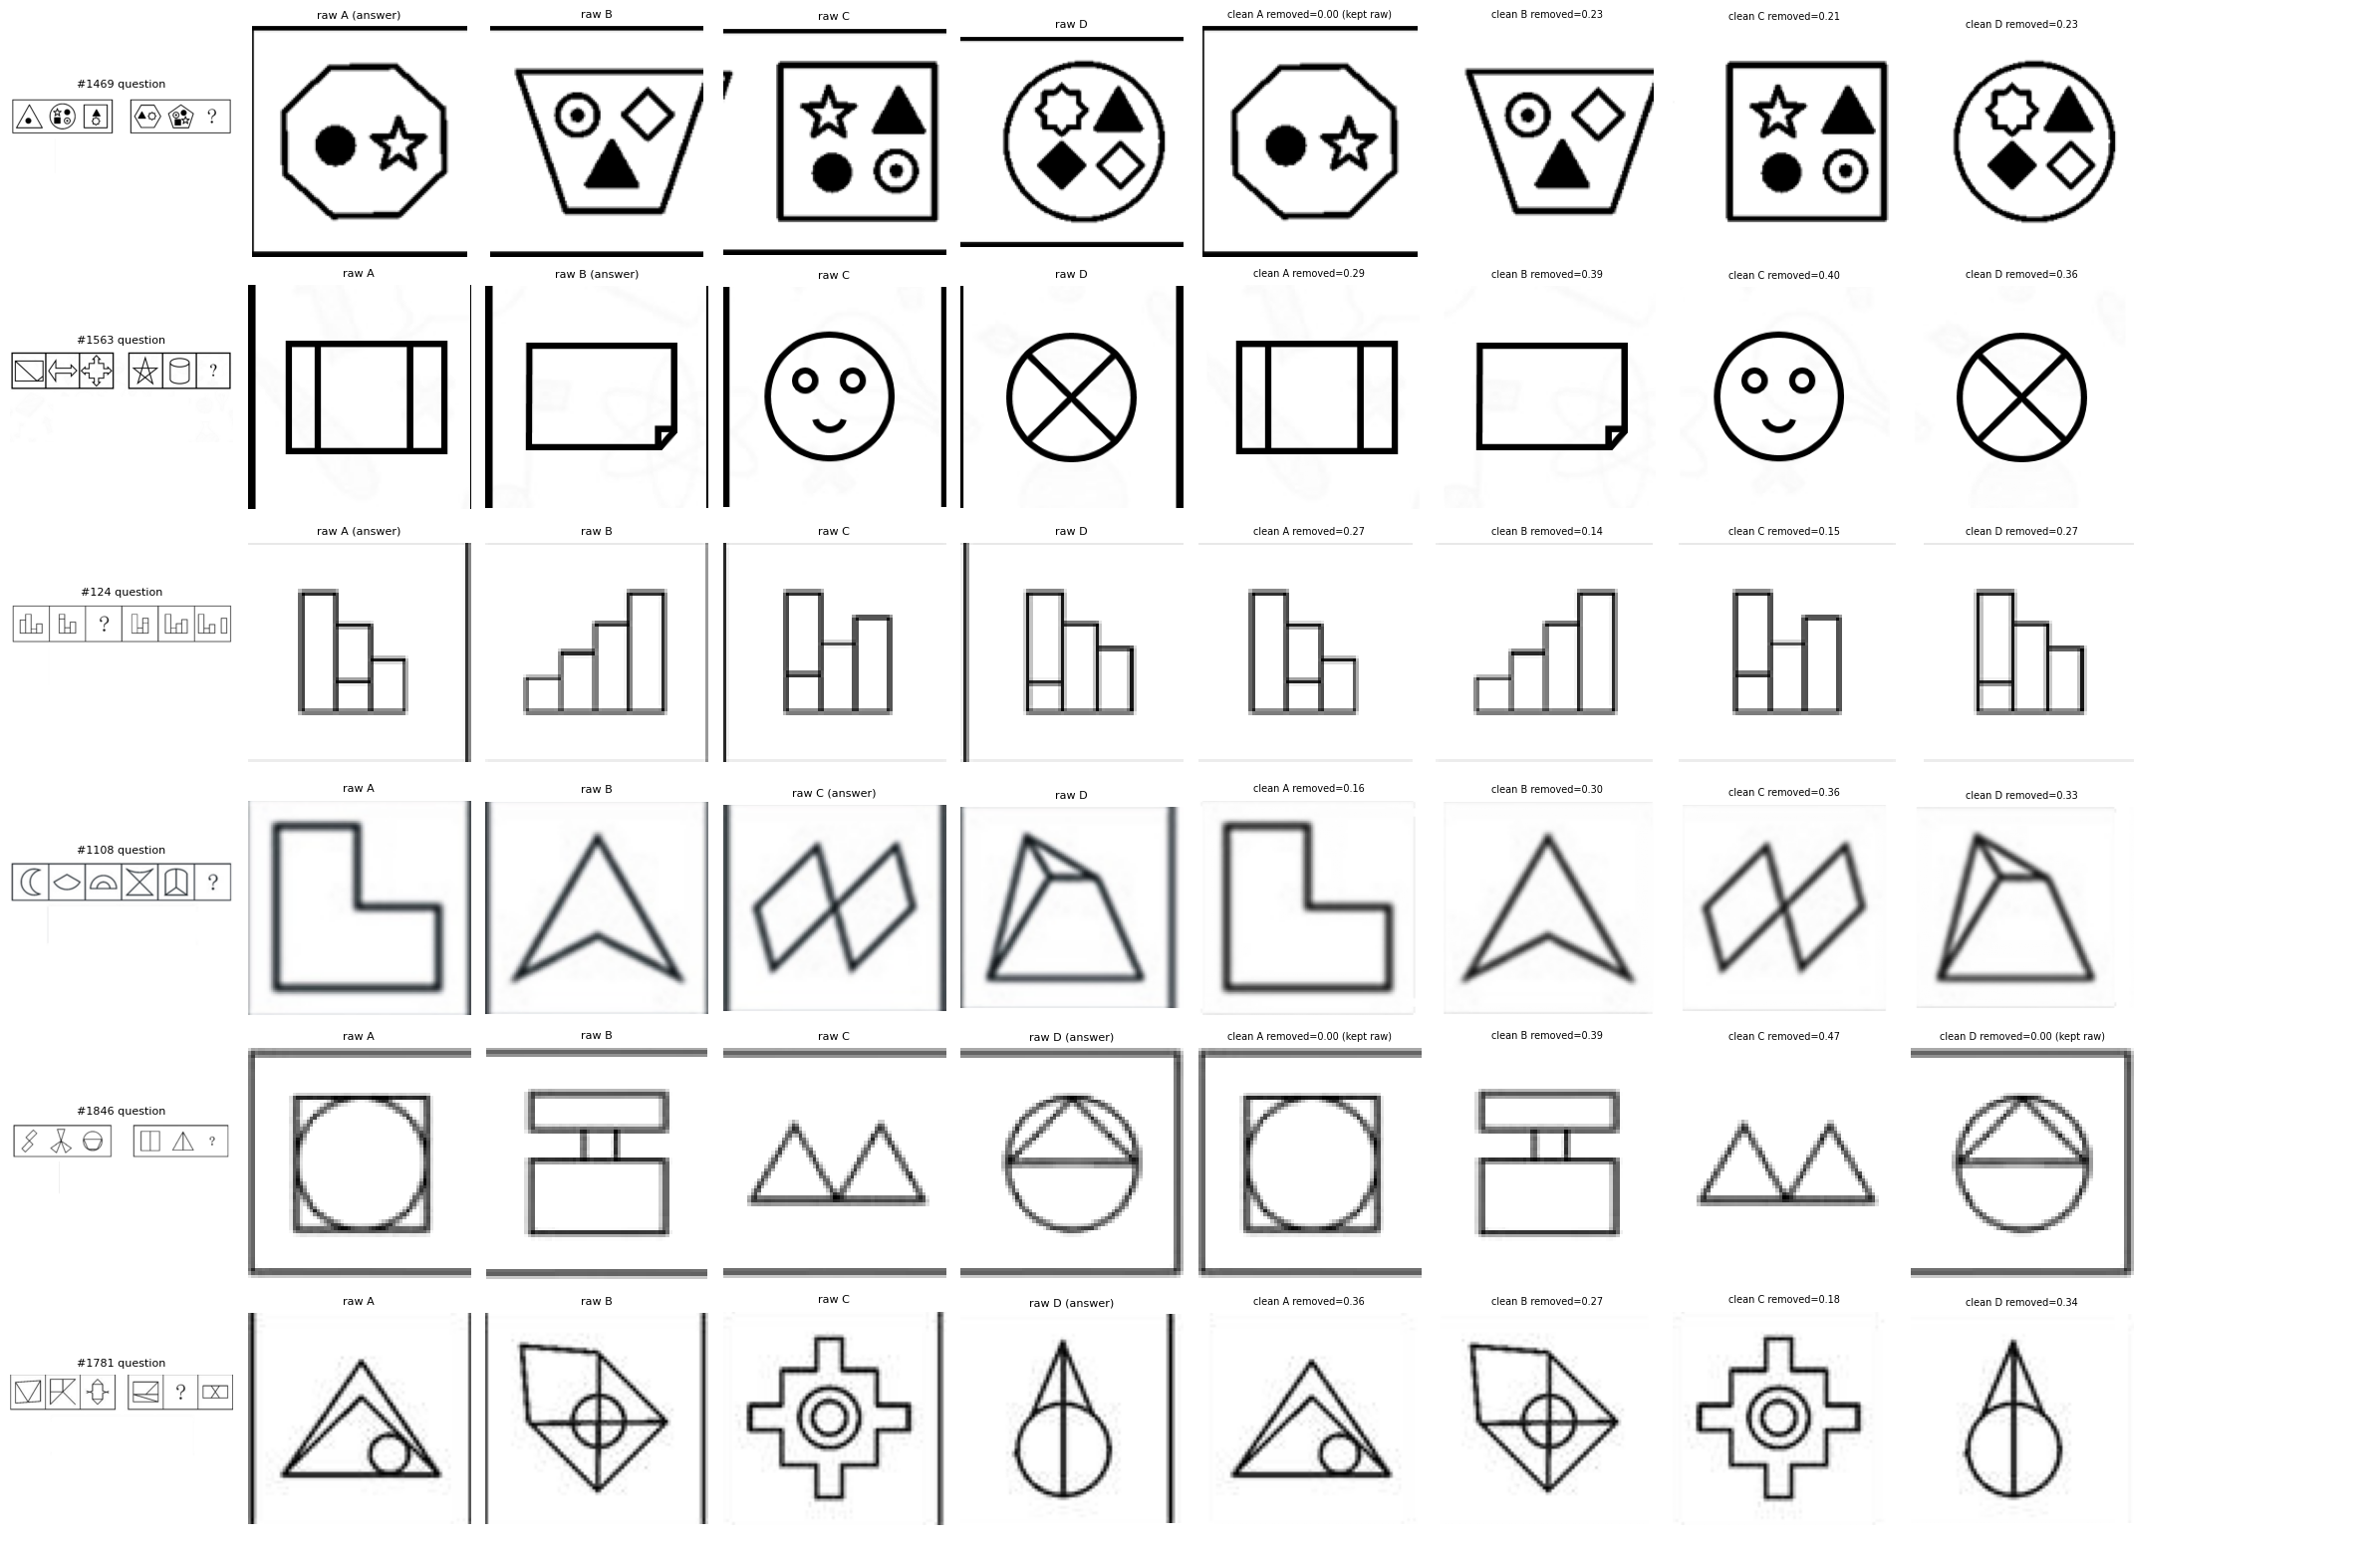

In [5]:
# From genveropt_stage3e.ipynb
ids = [1469, 1563, 124, 1108, 1846, 1781]
fig, axes = plt.subplots(len(ids), 10, figsize=(24, 2.6 * len(ids)), squeeze=False)
for row, i in enumerate(ids):
    r = extract(ds[i]["image"]); q = make_question(r)
    axes[row][0].imshow(q); axes[row][0].set_title(f"#{i} question", fontsize=8)
    ans = "ABCD".index(re.search("[A-D]", ds[i]["solution"].split("<answer>")[-1]).group())
    for k in range(4):
        cc, frac, applied = clean_crop2(r["crops"][k])
        axes[row][1 + k].imshow(r["crops"][k]); axes[row][1 + k].set_title(f"raw {'ABCD'[k]}{' (answer)' if k == ans else ''}", fontsize=8)
        axes[row][5 + k].imshow(cc, cmap="gray", vmin=0, vmax=255); axes[row][5 + k].set_title(f"clean {'ABCD'[k]} removed={frac:.2f}{'' if applied else ' (kept raw)'}", fontsize=7)
    axes[row][9].axis("off")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.savefig("/content/clean2_check.png", dpi=90); plt.show()

In [6]:
# From genveropt_stage3e.ipynb
from tqdm.auto import tqdm
QH, QW, OS = 96, 288, 96
rec, skipped = [], Counter()
Q, Oraw, Oclean, Y, IDX, REM = [], [], [], [], [], []
for i in tqdm(range(len(ds))):
    if "question mark" not in ds[i]["problem"].lower(): skipped["no_question_mark_prompt"] += 1; continue
    r = extract(ds[i]["image"])
    if not r["ok"]: skipped["not_parsed"] += 1; continue
    q = make_question(r)
    if float((np.asarray(q.convert("L")) < 200).mean()) < 0.002: skipped["empty_question"] += 1; IDX_EMPTY = None; rec.append(i); continue
    ans = "ABCD".index(re.search("[A-D]", ds[i]["solution"].split("<answer>")[-1]).group())
    raws, cleans, rems = [], [], []
    for c in r["crops"]:
        cc, frac, applied = clean_crop2(c)
        raws.append(np.asarray(letterbox(c, OS, OS))); cleans.append(np.asarray(letterbox(cc, OS, OS))); rems.append(frac if applied else 0.0)
    Q.append(np.asarray(letterbox(q, QH, QW))); Oraw.append(np.stack(raws)); Oclean.append(np.stack(cleans)); Y.append(ans); IDX.append(i); REM.append(rems)
Q, Oraw, Oclean, Y, IDX, REM = map(np.array, (Q, Oraw, Oclean, Y, IDX, REM))
print("usable:", len(Y), "| skipped:", dict(skipped))
print("answer distribution (usable):", dict(Counter(Y.tolist())))
print("crops where cleaning applied:", int((REM > 0).sum()), "of", REM.size, "| mean removed fraction when applied:", round(float(REM[REM > 0].mean()), 3) if (REM > 0).any() else 0)
print("items with near-empty question (excluded):", rec[:20])

  0%|          | 0/2710 [00:00<?, ?it/s]

usable: 1413 | skipped: {'no_question_mark_prompt': 1261, 'not_parsed': 34, 'empty_question': 2}
answer distribution (usable): {1: 368, 3: 353, 2: 353, 0: 339}
crops where cleaning applied: 3924 of 5652 | mean removed fraction when applied: 0.239
items with near-empty question (excluded): [819, 1292]


In [7]:
# From genveropt_stage3e.ipynb
rng = np.random.default_rng(0)
perm = rng.permutation(len(Y)); n_tr, n_va = int(0.7 * len(Y)), int(0.15 * len(Y))
split = {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}
for k, v in split.items(): print(k, len(v), "answer dist:", dict(sorted(Counter(Y[v].tolist()).items())))

# crude duplicate check: identical 96x96 raw option sets across different items (possible leakage between splits)
sigs = {}
for j in range(len(Y)):
    sigs.setdefault(Oraw[j].tobytes(), []).append(int(IDX[j]))
dups = [v for v in sigs.values() if len(v) > 1]
print("exact-duplicate option sets:", len(dups), dups[:5])

np.savez_compressed(f"/content/genveropt_mmiq_usable.npz", Q=Q, O_raw=Oraw, O_clean=Oclean, y=Y, idx=IDX,
                    train=split["train"], val=split["val"], test=split["test"])
import os; print("saved:", round(os.path.getsize("/content/genveropt_mmiq_usable.npz") / 1e6, 1), "MB")

train 989 answer dist: {0: 238, 1: 263, 2: 246, 3: 242}
val 211 answer dist: {0: 47, 1: 60, 2: 45, 3: 59}
test 213 answer dist: {0: 54, 1: 45, 2: 62, 3: 52}
exact-duplicate option sets: 5 [[99, 1803], [616, 2705], [1290, 1594], [1332, 1851], [1488, 1663, 2124]]
saved: 22.7 MB


In [8]:
import numpy as np, time, json
import torch, torch.nn as nn, torch.nn.functional as F
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)
z = np.load("/content/genveropt_mmiq_usable.npz")
Q, O_clean, O_raw, y, idx = z["Q"], z["O_clean"], z["O_raw"], z["y"], z["idx"]
N = len(y); print("items:", N, "| Q", Q.shape, "| O", O_clean.shape)

device: cuda
items: 1413 | Q (1413, 96, 288) | O (1413, 4, 96, 96)


## 1. Group-aware split (identical option sets stay together)

In [9]:
sig = {}
for j in range(N): sig.setdefault(O_raw[j].tobytes(), []).append(j)
groups = list(sig.values())
print("groups:", len(groups), "| multi-item groups:", sum(len(g) > 1 for g in groups))
rng = np.random.default_rng(0)
split = {"train": [], "val": [], "test": []}
n_tr, n_va = int(0.7 * N), int(0.15 * N)
cur = "train"
for g in rng.permutation(len(groups)):
    if cur == "train" and len(split["train"]) >= n_tr: cur = "val"
    if cur == "val" and len(split["val"]) >= n_va: cur = "test"
    split[cur] += groups[g]
split = {k: np.array(sorted(v)) for k, v in split.items()}
assert sum(len(v) for v in split.values()) == N and len(set(np.concatenate(list(split.values())))) == N
for k, v in split.items(): print(k, len(v), "answers:", {int(a): int(b) for a, b in zip(*np.unique(y[v], return_counts=True))})
CI = 1.96 * np.sqrt(0.25 * 0.75 / len(split["test"])); print(f"chance 0.25, ~95% half-width at n={len(split['test'])}: +/-{CI:.3f}")

groups: 1407 | multi-item groups: 5
train 989 answers: {0: 232, 1: 258, 2: 250, 3: 249}
val 211 answers: {0: 49, 1: 63, 2: 44, 3: 55}
test 213 answers: {0: 58, 1: 47, 2: 59, 3: 49}
chance 0.25, ~95% half-width at n=213: +/-0.058


## 2. Model and training code

In [10]:
Qt = torch.from_numpy(Q).to(dev); Ot = {"clean": torch.from_numpy(O_clean).to(dev), "raw": torch.from_numpy(O_raw).to(dev)}
yt = torch.from_numpy(y).long().to(dev)
POS_W = torch.tensor(3.0, device=dev)       # 1 positive : 3 negatives per puzzle

def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
class Enc(nn.Module):
    def __init__(self, pool, d=128):
        super().__init__()
        self.f = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 64), nn.AdaptiveAvgPool2d(pool), nn.Flatten())
        self.fc = nn.Sequential(nn.Linear(64 * pool[0] * pool[1], d), nn.ReLU(inplace=True), nn.Dropout(0.3))
    def forward(self, x): return self.fc(self.f(x))

class Verifier(nn.Module):
    def __init__(self, mode="both"):
        super().__init__(); self.mode = mode
        self.eo = Enc((3, 3)); self.eq = Enc((3, 6)) if mode == "both" else None
        din = 128 * (3 if mode == "both" else 1)
        self.head = nn.Sequential(nn.Linear(din, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 1))
    def forward(self, q, o):                      # q: B,1,96,288   o: B,4,1,96,96   ->  logits B,4
        B = o.shape[0]; eo = self.eo(o.flatten(0, 1))
        if self.mode == "both":
            eq = self.eq(q).repeat_interleave(4, dim=0)
            h = torch.cat([eq, eo, eq * eo], 1)
        else: h = eo
        return self.head(h).view(B, 4)

def batch(ids, okey):
    q = (1.0 - Qt[ids].float() / 255.0).unsqueeze(1)
    o = (1.0 - Ot[okey][ids].float() / 255.0).unsqueeze(2)
    return q, o, yt[ids]

@torch.no_grad()
def evaluate(m, ids, okey, shuffle_q=False, seed=0):
    m.eval(); ids = torch.as_tensor(ids, device=dev); correct = 0
    for i in range(0, len(ids), 128):
        b = ids[i:i + 128]; q, o, yy = batch(b, okey)
        if shuffle_q:
            g = torch.Generator().manual_seed(seed + i); q = q[torch.randperm(len(b), generator=g).to(dev)]
        correct += (m(q, o).argmax(1) == yy).sum().item()
    return correct / len(ids)

def run(mode, okey, seed, epochs=30, bs=32, lr=1e-3, verbose=False):
    torch.manual_seed(seed); np.random.seed(seed)
    m = Verifier(mode).to(dev); opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-4)
    tr = torch.as_tensor(split["train"], device=dev)
    best_va, best_state, best_ep = -1.0, None, -1
    for ep in range(epochs):
        m.train(); perm = tr[torch.randperm(len(tr), device=dev)]; tot = 0.0
        for i in range(0, len(perm), bs):
            q, o, yy = batch(perm[i:i + bs], okey)
            loss = F.binary_cross_entropy_with_logits(m(q, o), F.one_hot(yy, 4).float(), pos_weight=POS_W)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(yy)
        va = evaluate(m, split["val"], okey)
        if verbose: print(f"ep {ep:02d} train_loss {tot / len(tr):.4f} val_acc {va:.3f}")
        if va > best_va: best_va, best_ep, best_state = va, ep, {k: v.detach().clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state)
    return m, best_va, best_ep

## 3. Sanity run: one model, per-epoch curve (both inputs, cleaned options, seed 0)

In [11]:
t0 = time.time()
m, va, ep = run("both", "clean", seed=0, verbose=True)
print(f"best val {va:.3f} at epoch {ep} | test {evaluate(m, split['test'], 'clean'):.3f} | {time.time() - t0:.0f}s")

ep 00 train_loss 1.0475 val_acc 0.294
ep 01 train_loss 1.0443 val_acc 0.242
ep 02 train_loss 1.0426 val_acc 0.227
ep 03 train_loss 1.0408 val_acc 0.232
ep 04 train_loss 1.0408 val_acc 0.232
ep 05 train_loss 1.0374 val_acc 0.218
ep 06 train_loss 1.0394 val_acc 0.275
ep 07 train_loss 1.0401 val_acc 0.256
ep 08 train_loss 1.0337 val_acc 0.261
ep 09 train_loss 1.0356 val_acc 0.270
ep 10 train_loss 1.0232 val_acc 0.246
ep 11 train_loss 1.0103 val_acc 0.265
ep 12 train_loss 0.9844 val_acc 0.251
ep 13 train_loss 0.9637 val_acc 0.256
ep 14 train_loss 0.9351 val_acc 0.256
ep 15 train_loss 0.8779 val_acc 0.237
ep 16 train_loss 0.8050 val_acc 0.237
ep 17 train_loss 0.7374 val_acc 0.227
ep 18 train_loss 0.6509 val_acc 0.209
ep 19 train_loss 0.5909 val_acc 0.299
ep 20 train_loss 0.5110 val_acc 0.232
ep 21 train_loss 0.4954 val_acc 0.190
ep 22 train_loss 0.3996 val_acc 0.223
ep 23 train_loss 0.3521 val_acc 0.242
ep 24 train_loss 0.3594 val_acc 0.204
ep 25 train_loss 0.3301 val_acc 0.237
ep 26 train_

## 4. Grid: {question+option, option-only} x {cleaned, raw options} x 3 seeds
Test accuracy is computed once per run on the best-validation checkpoint. Takes roughly 20–30 minutes on a T4 (not measured).

In [12]:
results = []
for mode in ["both", "option_only"]:
    for okey in ["clean", "raw"]:
        for seed in [0, 1, 2]:
            m, va, ep = run(mode, okey, seed)
            r = dict(mode=mode, okey=okey, seed=seed, val=va, best_ep=ep, test=evaluate(m, split["test"], okey))
            if mode == "both": r["test_shuffled_q"] = float(np.mean([evaluate(m, split["test"], okey, True, s) for s in range(5)]))
            results.append(r); print(r)
json.dump(results, open("/content/stage4_results.json", "w"), indent=1)

print("\nmode / options        val (mean±sd)    test (mean±sd)   test w/ shuffled question")
for mode in ["both", "option_only"]:
    for okey in ["clean", "raw"]:
        rs = [r for r in results if r["mode"] == mode and r["okey"] == okey]
        f = lambda k: f"{np.mean([r[k] for r in rs]):.3f}±{np.std([r[k] for r in rs]):.3f}"
        sh = f("test_shuffled_q") if mode == "both" else "n/a"
        print(f"{mode:12s} {okey:6s}   {f('val'):14s}   {f('test'):14s}   {sh}")

{'mode': 'both', 'okey': 'clean', 'seed': 0, 'val': 0.3033175355450237, 'best_ep': 29, 'test': 0.27230046948356806, 'test_shuffled_q': 0.27230046948356806}
{'mode': 'both', 'okey': 'clean', 'seed': 1, 'val': 0.2890995260663507, 'best_ep': 19, 'test': 0.22065727699530516, 'test_shuffled_q': 0.22065727699530516}
{'mode': 'both', 'okey': 'clean', 'seed': 2, 'val': 0.2890995260663507, 'best_ep': 17, 'test': 0.24882629107981222, 'test_shuffled_q': 0.2488262910798122}
{'mode': 'both', 'okey': 'raw', 'seed': 0, 'val': 0.3127962085308057, 'best_ep': 12, 'test': 0.26291079812206575, 'test_shuffled_q': 0.26291079812206575}
{'mode': 'both', 'okey': 'raw', 'seed': 1, 'val': 0.3080568720379147, 'best_ep': 18, 'test': 0.24882629107981222, 'test_shuffled_q': 0.2488262910798122}
{'mode': 'both', 'okey': 'raw', 'seed': 2, 'val': 0.3033175355450237, 'best_ep': 12, 'test': 0.24413145539906103, 'test_shuffled_q': 0.24507042253521125}
{'mode': 'option_only', 'okey': 'clean', 'seed': 0, 'val': 0.31753554502

Send back: the section 3 printout (per-epoch curve and the final line) and the section 4 table plus the per-run dicts.